In [ ]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report)

In [ ]:
df = pd.read_csv('/content/sample_data/marketing_AB.csv')
df.head()

,user id,test group,converted,total ads,most ads day,most ads hour
0,1069124,ad,False,130,Monday,20
1,1119715,ad,False,93,Tuesday,22
2,1144181,ad,False,21,Tuesday,18
3,1435133,ad,False,355,Tuesday,10
4,1015700,ad,False,276,Friday,14


In [ ]:
shape = df.shape
columns = df.columns.tolist()
head_preview = df.head(10)

# Try to parse likely dates without failing hard
for col in df.columns:
    if any(key in col.lower() for key in ["date", "time", "timestamp"]):
        try:
            df[col] = pd.to_datetime(df[col], errors="ignore")
        except Exception:
            pass

In [ ]:
candidate_targets = [
    "lift_significant", "is_significant", "significant",
    "success", "test_success", "winner", "win",
    "outcome", "result",
    "converted", "conversion", "purchase", "label", "target"
]

found_target = None
for t in candidate_targets:
    if t in df.columns:
        # Check if binary-like
        unique_vals = df[t].dropna().unique()
        if len(unique_vals) == 2:
            found_target = t
            break
        # sometimes 0/1/True/False with more types
        # If numeric and can be coerced to {0,1}
        if pd.api.types.is_numeric_dtype(df[t]) and df[t].dropna().isin([0,1]).all():
            found_target = t
            break

# If not found, attempt to infer from common patterns (e.g., strings "yes/no", "true/false")
if found_target is None:
    for t in candidate_targets:
        if t in df.columns:
            # Try to map yes/no true/false win/lose etc. to 1/0
            vals = df[t].astype(str).str.lower().str.strip()
            unique_vals = set(vals.dropna().unique().tolist())
            binaries = [
                {"yes","no"}, {"true","false"}, {"win","lose"}, {"won","lost"},
                {"success","failure"}, {"b","a"}, {"1","0"}
            ]
            if any(unique_vals <= b or b <= unique_vals for b in binaries):
                # Convert to numeric 1/0
                mapping = {
                    "yes":1,"no":0,
                    "true":1,"false":0,
                    "win":1,"lose":0,
                    "won":1,"lost":0,
                    "success":1,"failure":0,
                    "1":1,"0":0,
                    "b":1,"a":0
                }
                df[t] = vals.map(mapping)
                found_target = t
                break

# If still not found, fallback: if there is a 'converted' like column with >2 classes, binarize >0
if found_target is None:
    for t in ["converted", "conversion", "purchase"]:
        if t in df.columns:
            df[t] = (df[t].astype(float) > 0).astype(int)
            found_target = t
            break

# If still nothing, raise a helpful error
if found_target is None:
    raise ValueError(
        "Could not automatically detect a binary target column.\n"
        "Please ensure the dataset has one of these columns as a binary label: "
        + ", ".join(candidate_targets)
    )

# Ensure binary numeric target (0/1)
if not pd.api.types.is_numeric_dtype(df[found_target]):
    df[found_target] = df[found_target].astype("category").cat.codes
# If codes are not 0/1, remap to 0/1
unique_target_vals = sorted(df[found_target].dropna().unique())
if unique_target_vals != [0,1]:
    # Map smallest to 0, largest to 1
    mapping = {unique_target_vals[0]:0, unique_target_vals[-1]:1}
    df[found_target] = df[found_target].map(mapping)

y = df[found_target].astype(int)

In [ ]:
exclude_like = [
    found_target,
    "id","user_id","session_id","visitor_id","experiment_id","exp_id","test_id",
    "uuid","guid"
]

# Keep 'group'/'variant' as features since the goal can also be session-level outcome prediction
id_like = set()
for c in df.columns:
    lc = c.lower()
    if lc in exclude_like or any(k in lc for k in exclude_like):
        id_like.add(c)

X = df.drop(columns=list(id_like), errors="ignore")

# Drop columns that are entirely NA or have a single unique value
drop_cols = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]
X = X.drop(columns=drop_cols, errors="ignore")

# Separate numeric vs categorical
numeric_features = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
categorical_features = [c for c in X.columns if c not in numeric_features and X[c].dtype.name != "datetime64[ns]"]

# Drop datetime cols for modeling
datetime_features = [c for c in X.columns if X[c].dtype.name == "datetime64[ns]"]
X = X.drop(columns=datetime_features, errors="ignore")

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y if y.nunique()==2 else None)

In [ ]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler(with_mean=False))  # with_mean=False works for sparse combos
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

# Logistic Regression
log_reg_clf = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("clf", LogisticRegression(max_iter=200, solver="liblinear"))
])

# Random Forest
rf_clf = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("clf", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced_subsample"))])

In [ ]:
log_reg_clf.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler(with_mean=False))]),
                                                  ['total ads',
                                                   'most ads hour']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['test group',
                                                   'most ads day'])])),
                ('clf', LogisticRegression(max_iter=200, solver='liblinear'))])

In [ ]:
rf_clf.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler(with_mean=False))]),
                                                  ['total ads',
                                                   'most ads hour']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['test group',
                                                   'most ads day'])])),
                ('clf',
                 RandomForestClassifier(class_weight='balanced_subsample',
                                        n_estimators=300, n_jobs=-1,
                                        random_state=42))])

In [ ]:
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    preds = model.predict(X_te)
    proba = None
    try:
        proba = model.predict_proba(X_te)[:,1]
    except Exception:
        pass
    metrics = {
        "model": name,
        "accuracy": accuracy_score(y_te, preds),
        "precision": precision_score(y_te, preds, zero_division=0),
        "recall": recall_score(y_te, preds, zero_division=0),
        "f1": f1_score(y_te, preds, zero_division=0),
    }
    if proba is not None and y_te.nunique()==2:
        try:
            metrics["roc_auc"] = roc_auc_score(y_te, proba)
        except Exception:
            metrics["roc_auc"] = np.nan
    else:
        metrics["roc_auc"] = np.nan
    return metrics, preds, proba

log_metrics, log_preds, log_proba = evaluate_model("LogisticRegression", log_reg_clf, X_train, y_train, X_test, y_test)
rf_metrics, rf_preds, rf_proba = evaluate_model("RandomForest", rf_clf, X_train, y_train, X_test, y_test)

metrics_df = pd.DataFrame([log_metrics, rf_metrics]).round(4)
metrics_df

,model,accuracy,precision,recall,f1,roc_auc
0,LogisticRegression,0.9736,0.2026,0.0155,0.0288,0.8176
1,RandomForest,0.8880,0.0794,0.3244,0.1275,0.6226


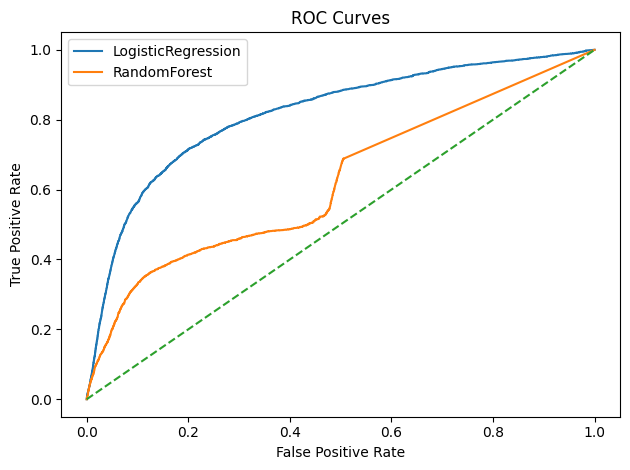

In [ ]:
plt.figure()
for name, proba in [("LogisticRegression", log_proba), ("RandomForest", rf_proba)]:
    if proba is not None:
        fpr, tpr, _ = roc_curve(y_test, proba)
        plt.plot(fpr, tpr, label=f"{name}")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
cm_log = confusion_matrix(y_test, log_preds)
cm_log

array([[114471,    181],
       [  2923,     46]])

**Streamlit implementation**

In [ ]:
!pip install streamlit
!wget https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb
!sudo dpkg -i cloudflared-linux-amd64.deb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 62.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 111.2 MB/s eta 0:00:00
--2025-08-23 16:31:24--  https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb
Resolving github.com (github.com)... 140.82.112.4
Connecting to github.com (github.com)|140.82.112.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://github.com/cloudflare/cloudflared/releases/download/2025.8.1/cloudflared-linux-amd64.deb [following]
--2025-08-23 16:31:24--  https://github.com/cloudflare/cloudflared/releases/download/2025.8.1/cloudflared-linux-amd64.deb
Reusing existing connection to github.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/106867604/92cb7978-e346-4125-ab19-54eebccb08b0?sp=r&sv=2018-11-09&sr=b&spr=https&se=2025-08-23T17%3A17%3A12Z&rscd=attachment%3B+fi

In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

st.title("📊 A/B Test Outcome Predictor")

# Upload dataset
uploaded_file = st.file_uploader("Upload your A/B Test dataset (CSV)", type=["csv"])

if uploaded_file is not None:
    # Load dataset
    df = pd.read_csv(uploaded_file)

    st.subheader("🔍 Dataset Preview")
    st.write(df.head())

    st.subheader("📈 Data Info")
    st.write(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
    st.write(df.describe())

    # Heatmap
    st.subheader("🔥 Correlation Heatmap")
    numeric_df = df.select_dtypes(include=["number"])  # only numeric cols
    if numeric_df.shape[1] > 1:  # at least 2 numeric cols needed
        plt.figure(figsize=(8,6))
        sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
        st.pyplot(plt)
    else:
        st.info("ℹ️ Not enough numeric columns to generate a correlation heatmap.")

    # Train/Test split
    if "test group" in df.columns and "converted" in df.columns:
        X = pd.get_dummies(df["test group"], drop_first=True)
        y = df["converted"]

        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=42
        )

        model = LogisticRegression()
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        # -----------------------------
        # Show actual predictions with confidence
        # -----------------------------
        st.subheader("📌 Prediction Samples")
        predictions_df = X_test.copy()
        predictions_df["Actual"] = y_test.values
        predictions_df["Predicted"] = y_pred
        predictions_df["Outcome"] = predictions_df.apply(
            lambda row: f"✅ Success" if row["Predicted"] == 1
                        else f"❌ Failure", axis=1
        )
        st.write(predictions_df.head(20))

        # Interactive user input
        st.subheader("🎯 Select Test Group")
        user_test_group = st.selectbox("Select Test Group", df["test group"].unique())
        user_input = pd.get_dummies([user_test_group], drop_first=True)
        # align with training columns
        user_input = user_input.reindex(columns=X_train.columns, fill_value=0)

        user_pred = model.predict(user_input)[0]

        if user_pred == 1:
            st.success(f"✅ Prediction: Likely SUCCESS")
        else:
            st.error(f"❌ Prediction: Likely FAILURE")
    else:
        st.error("Dataset must contain columns: 'test group' and 'converted'")
else:
    st.info("👆 Please upload a CSV file to start.")

Writing app.py


In [ ]:
!streamlit run app.py & npx cloudflared tunnel --url http://localhost:8501



⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙
  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.226.234.248:8501

⠹⠸⠼⠴⠦Need to install the following packages:
cloudflared@0.7.1
Ok to proceed? (y) y

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴2025-08-23T16:32:02Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2025-08-23T16:32:02Z INF Requesting new quick Tunnel on trycloudflare.com...
2025-08-23T16:32:06Z INF +-------